# DS-A3: Regression Baseline and Diagnostics
## 1. Introduction and Dataset
I predict a continuous measure of diabetes progression one year after baseline. I compare a mean baseline with three simple linear models using the original ten input features. This is a small coursework experiment, not a clinical prediction tool.

**Source:** [scikit-learn Diabetes dataset](https://scikit-learn.org/stable/datasets/toy_dataset.html#diabetes-dataset), distributed with scikit-learn; original data: [NCSU diabetes page](https://www4.stat.ncsu.edu/~boos/var.select/diabetes.html). `scaled=False` returns the raw inputs, so I can fit scaling inside each training fold. The response remains in its original target units.

In [1]:
import sys
import hashlib
import platform
from pathlib import Path
from importlib.metadata import version
from io import BytesIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import statsmodels.api as sm
from IPython.display import display, Markdown
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
alphas = [0.1, 1, 10, 100]
pd.set_option('display.max_columns', 12)
pd.set_option('display.float_format', lambda x: f'{x:.3f}')
plt.rcParams.update({'figure.figsize': (7, 3.6), 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.18, 'figure.dpi': 120})
BLUE, ORANGE = '#235789', '#b85c00'
figures = []
data = load_diabetes(scaled=False, as_frame=True)
X, y = data.data.copy(), data.target.copy()
print('Python:', platform.python_version(), '| scikit-learn:', sklearn.__version__)
print('Shape:', X.shape, '| target:', y.name)
print('Features:', ', '.join(X.columns))
print('Missing target:', y.isna().sum(), '| duplicate feature rows:', X.duplicated().sum())
display(pd.DataFrame({'dtype': X.dtypes.astype(str), 'missing': X.isna().sum(),
                      'minimum': X.min(), 'maximum': X.max()}))
assert X.shape == (442, 10) and not X.isna().any().any() and not y.isna().any()
data_hash = hashlib.sha256(pd.util.hash_pandas_object(data.frame, index=True).values.tobytes()).hexdigest()
print('Dataset SHA-256 (pandas row hashes):', data_hash)

Python: 3.12.14 | scikit-learn: 1.7.2
Shape: (442, 10) | target: target
Features: age, sex, bmi, bp, s1, s2, s3, s4, s5, s6
Missing target: 0 | duplicate feature rows: 0


,dtype,missing,minimum,maximum
age,float64,0,19.000,79.000
sex,float64,0,1.000,2.000
bmi,float64,0,18.000,42.200
bp,float64,0,62.000,133.000
s1,float64,0,97.000,301.000
s2,float64,0,41.600,242.400
s3,float64,0,22.000,99.000
s4,float64,0,2.000,9.090
s5,float64,0,3.258,6.107
s6,float64,0,58.000,124.000


Dataset SHA-256 (pandas row hashes): 194b29743afba0524a35dbc93e91b7a48750de8170323ee1d31c25585506b10b


## 2. Data Splitting and Leakage Audit
I freeze one random 80/20 split (`random_state=42`). Rounding gives 353 training rows and 89 test rows. All four models use the same shuffled five-fold training CV, also with seed 42. I choose the lowest mean CV MAE; an exact tie goes to the first model in the declared order: Dummy, Linear, Ridge, Lasso. For an alpha tie, I use the first value in the grid.

The mean baseline learns the **training** target mean. Although a median minimizes MAE, the assignment specifically asks for a mean baseline. Every linear model uses `StandardScaler` inside its pipeline, so each CV fold fits preprocessing only on that fold's training rows. There is no imputation, feature engineering, or target transformation. Test targets cannot affect alpha selection or the final model choice. BMI group boundaries will also come only from the training set.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv_splits = list(cv.split(X_train))
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_train.index) | set(X_test.index) == set(X.index)
assert len(X_train) == 353 and len(X_test) == 89
for train_pos, valid_pos in cv_splits:
    assert set(train_pos).isdisjoint(valid_pos)
    assert len(train_pos) + len(valid_pos) == len(X_train)
print('Train:', len(X_train), '| test:', len(X_test), '| CV folds:', len(cv_splits))
print('Frozen test row IDs:', X_test.index.tolist())
split_hash = hashlib.sha256(np.asarray(X_test.index, dtype='<i8').tobytes()).hexdigest()
print('Ordered test row ID SHA-256:', split_hash)
print('Audit: disjoint split, original ten features, fold-local pipelines, training-only CV.')

Train: 353 | test: 89 | CV folds: 5
Frozen test row IDs: [287, 211, 72, 321, 73, 418, 367, 354, 281, 148, 429, 78, 126, 113, 329, 427, 172, 268, 76, 116, 9, 181, 55, 399, 30, 140, 341, 209, 436, 132, 407, 79, 39, 333, 311, 422, 75, 157, 307, 370, 70, 227, 284, 402, 199, 82, 77, 33, 358, 395, 411, 131, 11, 386, 15, 104, 196, 0, 19, 286, 320, 56, 244, 101, 218, 291, 409, 388, 374, 25, 185, 203, 117, 42, 296, 423, 155, 440, 176, 285, 22, 46, 93, 433, 255, 90, 57, 391, 24]
Ordered test row ID SHA-256: 02d2e32a71061a4379a53ff2ea22f29e8c3a6971b6ffb1a08a5fb77b8dd90ac0
Audit: disjoint split, original ten features, fold-local pipelines, training-only CV.


## 3. Baseline and Model Training
I compare only Dummy, Linear, Ridge, and Lasso. The two regularized models search the same four alpha values. MAE is the selection metric; RMSE and R-squared will describe the final test errors. CV standard deviation describes variation across these folds, not a confidence interval. All CV results, including poor alpha settings, are kept below.

In [3]:
candidates = {
    'Dummy': DummyRegressor(strategy='mean'),
    'Linear': Pipeline([('scale', StandardScaler()), ('reg', LinearRegression())]),
    'Ridge': Pipeline([('scale', StandardScaler()), ('reg', Ridge())]),
    'Lasso': Pipeline([('scale', StandardScaler()), ('reg', Lasso(max_iter=10000))])
}
fitted = {}
cv_rows, alpha_rows = [], []
for name, estimator in candidates.items():
    if name in ('Ridge', 'Lasso'):
        search = GridSearchCV(estimator, {'reg__alpha': alphas}, cv=cv_splits,
                              scoring='neg_mean_absolute_error', refit=True,
                              n_jobs=1, error_score='raise')
        search.fit(X_train, y_train)
        fitted[name] = search.best_estimator_
        best_alpha = search.best_params_['reg__alpha']
        scores = -np.array([search.cv_results_[f'split{k}_test_score'][search.best_index_]
                            for k in range(5)])
        for i, params in enumerate(search.cv_results_['params']):
            row = {'Model': name, 'alpha': params['reg__alpha'],
                   'CV_MAE': -search.cv_results_['mean_test_score'][i],
                   'CV_SD': search.cv_results_['std_test_score'][i],
                   'chosen': i == search.best_index_}
            row.update({f'fold_{k+1}_MAE': -search.cv_results_[f'split{k}_test_score'][i]
                        for k in range(5)})
            alpha_rows.append(row)
    else:
        scores = -cross_val_score(estimator, X_train, y_train, cv=cv_splits,
                                  scoring='neg_mean_absolute_error', error_score='raise')
        fitted[name] = estimator.fit(X_train, y_train)
        best_alpha = np.nan
    cv_rows.append({'Model': name, 'alpha': best_alpha, 'CV_MAE': scores.mean(),
                    'CV_SD': scores.std(ddof=0)})
cv_table = pd.DataFrame(cv_rows).set_index('Model')
alpha_table = pd.DataFrame(alpha_rows)
display(alpha_table)
print('All 8 alpha configurations and all 40 fold MAEs are retained above.')

,Model,alpha,CV_MAE,CV_SD,chosen,fold_1_MAE,fold_2_MAE,fold_3_MAE,fold_4_MAE,fold_5_MAE
0,Ridge,0.100,45.041,1.777,False,44.575,48.268,42.893,44.317,45.153
1,Ridge,1.000,44.999,1.808,True,44.473,48.208,42.678,44.422,45.214
2,Ridge,10.000,45.060,1.951,False,44.544,48.336,42.256,44.787,45.379
3,Ridge,100.000,46.047,2.869,False,44.615,50.904,42.174,46.722,45.822
4,Lasso,0.100,44.956,1.837,True,44.434,48.209,42.564,44.443,45.128
5,Lasso,1.000,45.136,1.991,False,44.404,48.355,42.194,45.070,45.656
6,Lasso,10.000,48.298,3.496,False,46.161,53.531,43.161,48.737,49.901
7,Lasso,100.000,66.867,5.632,False,62.863,74.052,58.431,67.769,71.222


All 8 alpha configurations and all 40 fold MAEs are retained above.


In [4]:
# Freeze the choice before any test prediction or test metric is calculated.
selected_name = cv_table['CV_MAE'].idxmin()
final_model = fitted[selected_name]
selection = {'model': selected_name, 'alpha': cv_table.loc[selected_name, 'alpha'],
             'CV_MAE': cv_table.loc[selected_name, 'CV_MAE']}
display(cv_table)
print('TRAINING-ONLY SELECTION FROZEN:', selection)
assert len(alpha_table) == 8
for name in ('Linear', 'Ridge', 'Lasso'):
    scaler = fitted[name].named_steps['scale']
    assert scaler.n_samples_seen_ == len(X_train)
    np.testing.assert_allclose(scaler.mean_, X_train.mean().to_numpy())
assert np.isclose(fitted['Dummy'].constant_.item(), y_train.mean())

,alpha,CV_MAE,CV_SD
Model,,,
Dummy,NaN,66.867,5.632
Linear,NaN,45.048,1.773
Ridge,1.000,44.999,1.808
Lasso,0.100,44.956,1.837


TRAINING-ONLY SELECTION FROZEN: {'model': 'Lasso', 'alpha': np.float64(0.1), 'CV_MAE': np.float64(44.95557819859468)}


## 4. Model Comparison
The choice is now fixed. I evaluate the four fitted candidates on the held-out test set once. Reporting their test scores is descriptive and cannot change the choice above. Residual means `actual - predicted`; positive residuals indicate underprediction. MAE and RMSE use target units; R-squared is unitless.

In [5]:
comparison = cv_table.copy()
results = pd.DataFrame({'sample_id': X_test.index, 'actual': y_test.to_numpy(),
                        'bmi': X_test['bmi'].to_numpy()})
for name, model in fitted.items():
    pred = model.predict(X_test)
    comparison.loc[name, 'Test_MAE'] = mean_absolute_error(y_test, pred)
    comparison.loc[name, 'Test_RMSE'] = np.sqrt(mean_squared_error(y_test, pred))
    comparison.loc[name, 'Test_R2'] = r2_score(y_test, pred)
    results[f'{name}_predicted'] = pred
    results[f'{name}_residual'] = y_test.to_numpy() - pred
    results[f'{name}_absolute_error'] = np.abs(y_test.to_numpy() - pred)
comparison['selected_by_CV'] = comparison.index == selected_name
predicted = results[f'{selected_name}_predicted'].to_numpy()
residual = y_test.to_numpy() - predicted
results['selected_model'] = selected_name
results['predicted'] = predicted
results['residual'] = residual
results['absolute_error'] = np.abs(residual)
display(comparison)
assert selected_name == selection['model']
performance_note = (f'{selected_name} was selected using CV MAE {selection["CV_MAE"]:.3f}. '
                    f'Its test MAE is {comparison.loc[selected_name, "Test_MAE"]:.3f}, '
                    f'RMSE is {comparison.loc[selected_name, "Test_RMSE"]:.3f}, and '
                    f'R-squared is {comparison.loc[selected_name, "Test_R2"]:.3f}. '
                    'The test ranking is not used for model selection.')
display(Markdown(performance_note))

,alpha,CV_MAE,CV_SD,Test_MAE,Test_RMSE,Test_R2,selected_by_CV
Model,,,,,,,
Dummy,NaN,66.867,5.632,64.006,73.222,-0.012,False
Linear,NaN,45.048,1.773,42.794,53.853,0.453,False
Ridge,1.000,44.999,1.808,42.812,53.777,0.454,False
Lasso,0.100,44.956,1.837,42.805,53.709,0.456,True


Lasso was selected using CV MAE 44.956. Its test MAE is 42.805, RMSE is 53.709, and R-squared is 0.456. The test ranking is not used for model selection.

## 5. Diagnostics and Error Analysis
These diagnostics inspect the preselected model. They do not trigger tuning or sample removal. The exception is Cook's distance: the assignment asks for a separate training-only OLS fit as a linear influence diagnostic. It is not a fifth prediction candidate.

### Figure 1: Residuals vs Predicted Values
The orange line joins average residuals in four prediction quantile bins. It is a descriptive guide, not a fitted correction.

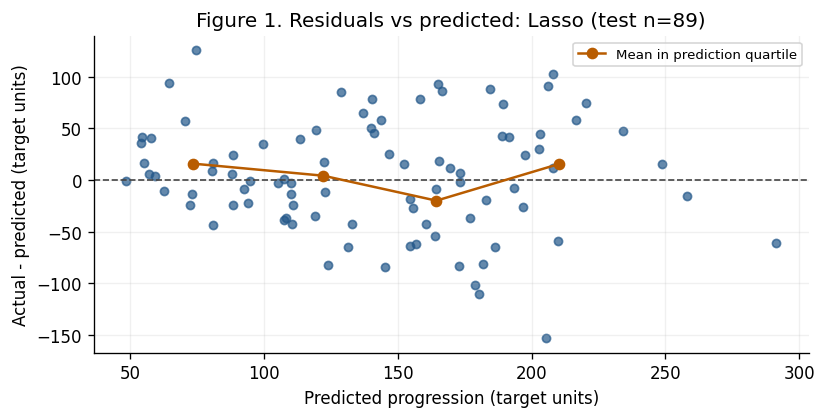

,n,mean_prediction,mean_residual,MAE
bin,,,,
"(48.623000000000005, 99.8]",23,73.669,15.766,28.713
"(99.8, 143.666]",22,122.128,4.145,40.309
"(143.666, 181.937]",22,164.426,-20.017,50.460
"(181.937, 291.372]",22,210.156,15.389,52.379


The mean test residual is 3.96. The lowest and highest prediction bins have mean residuals 15.77 and 15.39. The third bin has mean residual -20.02, indicating local overprediction. The low and high bins show underprediction on average. There is substantial scatter around zero. Bin means help check local bias, but 89 test rows cannot establish a stable calibration pattern.

In [6]:
prediction_bins = pd.qcut(predicted, q=4, duplicates='drop')
residual_summary = pd.DataFrame({'predicted': predicted, 'residual': residual,
                                 'absolute_error': np.abs(residual), 'bin': prediction_bins})
bin_summary = residual_summary.groupby('bin', observed=True).agg(
    n=('residual', 'size'), mean_prediction=('predicted', 'mean'),
    mean_residual=('residual', 'mean'), MAE=('absolute_error', 'mean'))
fig, ax = plt.subplots()
ax.scatter(predicted, residual, color=BLUE, alpha=0.7, s=24)
ax.axhline(0, color='#444444', linestyle='--', linewidth=1)
ax.plot(bin_summary['mean_prediction'], bin_summary['mean_residual'], 'o-',
        color=ORANGE, label='Mean in prediction quartile')
ax.set(title=f'Figure 1. Residuals vs predicted: {selected_name} (test n={len(y_test)})',
       xlabel='Predicted progression (target units)', ylabel='Actual - predicted (target units)')
ax.legend(loc='best', fontsize=8)
fig.tight_layout()
figures.append(fig)
plt.show()
plt.close(fig)
display(bin_summary)
residual_note = (f'The mean test residual is {residual.mean():.2f}. '
                 f'The lowest and highest prediction bins have mean residuals '
                 f'{bin_summary["mean_residual"].iloc[0]:.2f} and '
                 f'{bin_summary["mean_residual"].iloc[-1]:.2f}. '
                 f'The third bin has mean residual {bin_summary["mean_residual"].iloc[2]:.2f}, indicating local overprediction. '
                 'The low and high bins show underprediction on average. There is substantial '
                 'scatter around zero. Bin means help check local bias, '
                 'but 89 test rows cannot establish a stable calibration pattern.')
display(Markdown(residual_note))

### Figure 2: Absolute Residuals vs Predicted Values
If the spread changes with predicted values, constant error variance may be doubtful. I compare bin MAEs visually rather than using a formal hypothesis test.

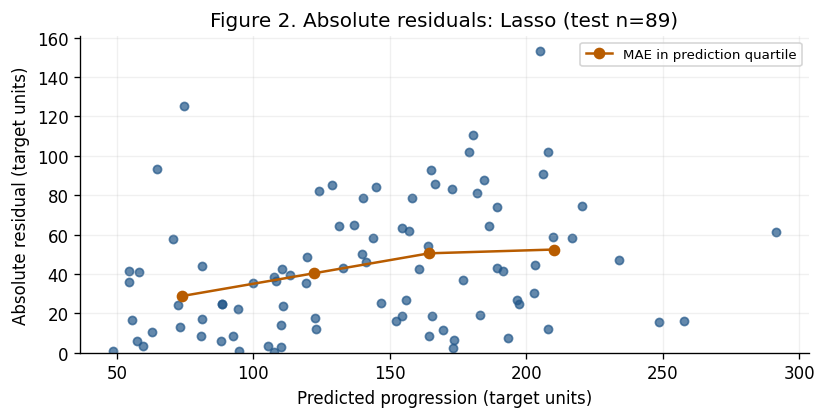

MAE across prediction quartiles ranges from 28.71 to 52.38. The size of errors varies across the prediction range, so constant variance should not be assumed. The pattern is descriptive evidence, not proof of heteroscedasticity or a reason to retune on this test set.

In [7]:
fig, ax = plt.subplots()
ax.scatter(predicted, np.abs(residual), color=BLUE, alpha=0.7, s=24)
ax.plot(bin_summary['mean_prediction'], bin_summary['MAE'], 'o-', color=ORANGE,
        label='MAE in prediction quartile')
ax.set(title=f'Figure 2. Absolute residuals: {selected_name} (test n={len(y_test)})',
       xlabel='Predicted progression (target units)', ylabel='Absolute residual (target units)', ylim=(0, None))
ax.legend(loc='best', fontsize=8)
fig.tight_layout()
figures.append(fig)
plt.show()
plt.close(fig)
variance_note = (f'MAE across prediction quartiles ranges from {bin_summary["MAE"].min():.2f} '
                 f'to {bin_summary["MAE"].max():.2f}. '
                 'The size of errors varies across the prediction range, so constant variance '
                 'should not be assumed. The pattern is descriptive evidence, not proof of '
                 'heteroscedasticity or a reason to retune on this test set.')
display(Markdown(variance_note))

### Figure 3: Cook's Distance
I fit statsmodels OLS with an intercept and all ten predictors, scaled using training rows only. Scaling does not change OLS fitted values or Cook's distance. `4 / n_train` is a screening rule, not a formal outlier test. Labels are original dataset row IDs.

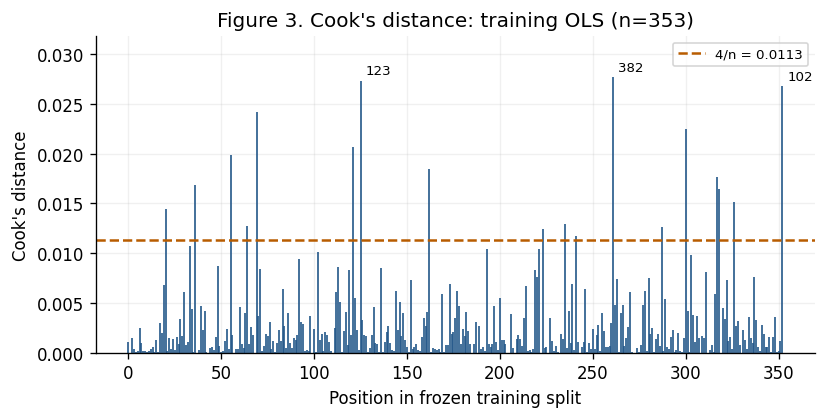

,sample_id,cooks_distance,leverage,actual,bmi
261,382,0.028,0.063,132.000,32.000
125,123,0.027,0.090,84.000,29.600
352,102,0.027,0.032,302.000,29.000
69,304,0.024,0.043,253.000,22.800
300,387,0.022,0.057,201.000,27.800


18 training rows exceed 4/n = 0.0113. The largest distance is 0.0277, at original row 382. Influential observations can move the OLS coefficients and fitted values. They are not automatically incorrect. No rows are removed; this OLS measure is not an exact influence measure for a penalized final model.

In [8]:
ols_scaler = StandardScaler().fit(X_train)
ols_X = sm.add_constant(ols_scaler.transform(X_train))
ols_fit = sm.OLS(y_train.to_numpy(), ols_X).fit()
np.testing.assert_allclose(ols_fit.predict(ols_X), fitted['Linear'].predict(X_train), rtol=1e-8)
cook = ols_fit.get_influence().cooks_distance[0]
cook_threshold = 4 / len(X_train)
influence_table = pd.DataFrame({'sample_id': X_train.index, 'cooks_distance': cook,
                                 'leverage': ols_fit.get_influence().hat_matrix_diag,
                                 'actual': y_train.to_numpy(), 'bmi': X_train['bmi'].to_numpy()})
fig, ax = plt.subplots()
ax.vlines(np.arange(len(cook)), 0, cook, color=BLUE, linewidth=1)
ax.axhline(cook_threshold, color=ORANGE, linestyle='--', label=f'4/n = {cook_threshold:.4f}')
for pos in np.argsort(cook)[-3:]:
    ax.annotate(str(X_train.index[pos]), (pos, cook[pos]), xytext=(3, 4),
                textcoords='offset points', fontsize=8)
ax.set(title=f"Figure 3. Cook's distance: training OLS (n={len(X_train)})",
       xlabel='Position in frozen training split', ylabel="Cook's distance", ylim=(0, cook.max()*1.15))
ax.legend(fontsize=8)
fig.tight_layout()
figures.append(fig)
plt.show()
plt.close(fig)
display(influence_table.nlargest(5, 'cooks_distance'))
influence_note = (f'{int((cook > cook_threshold).sum())} training rows exceed 4/n = {cook_threshold:.4f}. '
                  f'The largest distance is {cook.max():.4f}, at original row '
                  f'{int(influence_table.loc[influence_table["cooks_distance"].idxmax(), "sample_id"])}. '
                  'Influential observations can move the OLS coefficients and fitted values. '
                  'They are not automatically incorrect. No rows are removed; '
                  'this OLS measure is not an exact influence measure for a penalized final model.')
display(Markdown(influence_note))

### Figure 4: Learning Curve
I use only the 353 training rows and the same five fold assignments. The final model and alpha stay fixed. Each smaller training subset fits its own pipeline. Shading is plus/minus one fold standard deviation, not a confidence interval. Because these training folds also helped select alpha, this is a descriptive curve rather than an independent validation estimate.

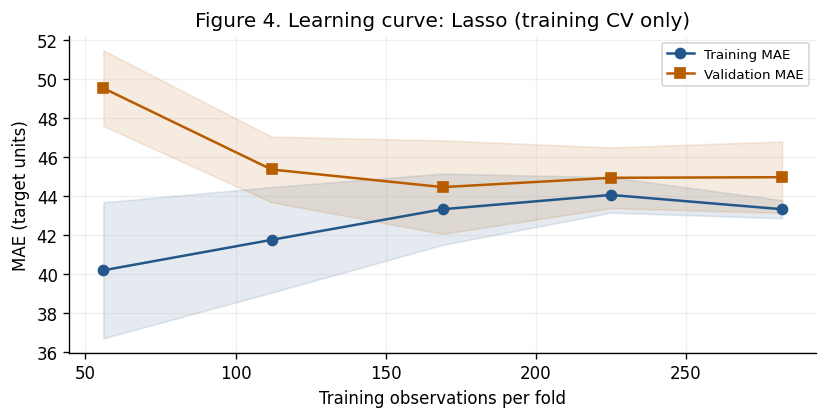

,training_rows_per_fold,train_MAE,validation_MAE,train_SD,validation_SD
0,56,40.183,49.532,3.490,1.941
1,112,41.746,45.358,2.710,1.684
2,169,43.319,44.453,1.830,2.397
3,225,44.052,44.932,0.909,1.555
4,282,43.319,44.963,0.463,1.834


Validation MAE changes from 49.53 at 56 rows to 44.96 at 282 rows per fold. At the largest size, training MAE is 43.32, leaving a 1.64-unit gap. The small final gap does not suggest severe overfitting. Validation error levels off after the first few sizes. More data may help, but the remaining error may also reflect noise and a limited linear model; the curve cannot separate these explanations.

In [9]:
train_sizes, train_scores, valid_scores = learning_curve(
    final_model, X_train, y_train, cv=cv_splits, scoring='neg_mean_absolute_error',
    train_sizes=[0.2, 0.4, 0.6, 0.8, 1.0], shuffle=True, random_state=SEED,
    n_jobs=1, error_score='raise')
train_mae, valid_mae = -train_scores, -valid_scores
learning_table = pd.DataFrame({'training_rows_per_fold': train_sizes,
    'train_MAE': train_mae.mean(axis=1), 'validation_MAE': valid_mae.mean(axis=1),
    'train_SD': train_mae.std(axis=1), 'validation_SD': valid_mae.std(axis=1)})
fig, ax = plt.subplots()
for values, color, label, marker in [(train_mae, BLUE, 'Training MAE', 'o'),
                                      (valid_mae, ORANGE, 'Validation MAE', 's')]:
    avg, sd = values.mean(axis=1), values.std(axis=1)
    ax.plot(train_sizes, avg, marker=marker, color=color, label=label)
    ax.fill_between(train_sizes, avg-sd, avg+sd, color=color, alpha=0.12)
ax.set(title=f'Figure 4. Learning curve: {selected_name} (training CV only)',
       xlabel='Training observations per fold', ylabel='MAE (target units)')
ax.legend(fontsize=8)
fig.tight_layout()
figures.append(fig)
plt.show()
plt.close(fig)
display(learning_table)
learning_note = (f'Validation MAE changes from {valid_mae.mean(axis=1)[0]:.2f} at '
                 f'{train_sizes[0]} rows to {valid_mae.mean(axis=1)[-1]:.2f} at '
                 f'{train_sizes[-1]} rows per fold. At the largest size, training MAE is '
                 f'{train_mae.mean(axis=1)[-1]:.2f}, leaving a '
                 f'{valid_mae.mean(axis=1)[-1]-train_mae.mean(axis=1)[-1]:.2f}-unit gap. '
                 'The small final gap does not suggest severe overfitting. Validation error '
                 'levels off after the first few sizes. More data may help, '
                 'but the remaining error may also reflect noise and a limited linear model; '
                 'the curve cannot separate these explanations.')
display(Markdown(learning_note))

### Critical Slices
Low, middle, and high BMI are relative groups defined by the training BMI tertiles. These are not medical categories. The right-closed intervals are `(-inf, q1]`, `(q1, q2]`, and `(q2, inf)`.

In [10]:
bmi_q1, bmi_q2 = X_train['bmi'].quantile([1/3, 2/3]).to_numpy()
results['bmi_slice'] = pd.cut(results['bmi'], bins=[-np.inf, bmi_q1, bmi_q2, np.inf],
                              labels=['Low', 'Middle', 'High'], right=True)
slice_table = results.groupby('bmi_slice', observed=False).agg(
    n=('absolute_error', 'size'), MAE=('absolute_error', 'mean'))
print(f'Training BMI boundaries: q1={bmi_q1:.4f}, q2={bmi_q2:.4f}')
display(slice_table)
assert slice_table['n'].sum() == len(y_test)
worst_slice = slice_table['MAE'].idxmax()
slice_note = (f'The {worst_slice.lower()} BMI group has the largest test MAE '
              f'({slice_table.loc[worst_slice, "MAE"]:.2f}, '
              f'n={slice_table.loc[worst_slice, "n"]}). '
              'Group counts are small and unequal, so this is a descriptive '
              'difference on one split, not a population fairness or clinical finding.')
display(Markdown(slice_note))

Training BMI boundaries: q1=24.2000, q2=27.9000


,n,MAE
bmi_slice,,
Low,38,34.490
Middle,23,47.433
High,28,50.288


The high BMI group has the largest test MAE (50.29, n=28). Group counts are small and unequal, so this is a descriptive difference on one split, not a population fairness or clinical finding.

### Error Cases
I inspect the three largest test absolute errors for the frozen model. Row IDs connect the table to the original dataset and `results.csv`.

In [11]:
error_cases = results.nlargest(3, 'absolute_error')[
    ['sample_id', 'actual', 'predicted', 'absolute_error', 'bmi', 'bmi_slice']]
display(error_cases)
error_note = (f'The three largest absolute errors range from '
              f'{error_cases["absolute_error"].min():.2f} to {error_cases["absolute_error"].max():.2f} '
              'target units. Rows 56 and 211 have high BMI but low actual targets and are '
              'overpredicted; row 77 has low BMI but a high actual target and is underpredicted. '
              'People with similar measured inputs can still have different outcomes, '
              'and the model may miss unmeasured factors or nonlinear patterns. '
              'These are possible explanations, not verified causes. '
              'I do not change the model or alpha after inspecting these cases.')
display(Markdown(error_note))
results.to_csv('results.csv', index=False, float_format='%.10f')
print('Saved results.csv:', len(results), 'held-out rows and all four model predictions.')

,sample_id,actual,predicted,absolute_error,bmi,bmi_slice
61,56,52.000,205.195,153.195,30.200,High
46,77,200.000,74.619,125.381,23.000,Low
1,211,70.000,180.323,110.323,29.800,High


The three largest absolute errors range from 110.32 to 153.20 target units. Rows 56 and 211 have high BMI but low actual targets and are overpredicted; row 77 has low BMI but a high actual target and is underpredicted. People with similar measured inputs can still have different outcomes, and the model may miss unmeasured factors or nonlinear patterns. These are possible explanations, not verified causes. I do not change the model or alpha after inspecting these cases.

Saved results.csv: 89 held-out rows and all four model predictions.


## 6. Discussion and Limitations
The comparison is based on training CV. The held-out set is used only for the final scores and diagnostics. The following numbers are generated from the experiment above.

In [12]:
linear_cv = cv_table.loc['Linear', 'CV_MAE']
ridge_gain = linear_cv - cv_table.loc['Ridge', 'CV_MAE']
lasso_gain = linear_cv - cv_table.loc['Lasso', 'CV_MAE']
complexity_note = (f'Ridge improves CV MAE over ordinary linear regression by {ridge_gain:.3f} '
                   f'({100*ridge_gain/linear_cv:.2f}%), and Lasso by {lasso_gain:.3f} '
                   f'({100*lasso_gain/linear_cv:.2f}%). '
                   'A positive value means lower error. The gains are too small here to claim a '
                   'meaningful practical improvement. These differences must be judged '
                   'against the fold variation in the table; this experiment does not '
                   'establish a statistically reliable improvement. '
                   'Both add a tuning choice; Lasso can also set coefficients to zero, '
                   f'but the selected Lasso retains {np.count_nonzero(fitted["Lasso"].named_steps["reg"].coef_)} of ten coefficients.')
causal_note = ('Regression coefficients are conditional associations, not treatment effects. '
              'This is observational data without random assignment. Unmeasured confounding, '
              'correlated predictors, measurement error, and model assumptions can affect '
              'their signs and sizes. Regularization deliberately shrinks coefficients. '
              'Changing a feature would not necessarily cause the predicted outcome change.')
limitations_note = ('This experiment uses 442 observations, one random split, and ten baseline '
                   'features. Only 89 rows support the test diagnostics, and subgroup counts '
                   'are smaller. There is no external validation, prediction interval, or '
                   'formal heteroscedasticity test. CV is reused for selection, so the best '
                   'CV score may be optimistic; its fold standard deviation is not a '
                   'significance test. Simple linear models may miss nonlinear relationships '
                   'and omitted variables. These results cannot support clinical decisions '
                   'or causal claims.')
discussion_notes = [performance_note, complexity_note, residual_note, variance_note,
                    influence_note, learning_note, slice_note, causal_note, limitations_note]
for note in discussion_notes:
    display(Markdown(note))
coefficient_table = pd.DataFrame({'feature': X.columns,
    'coefficient_per_training_SD': final_model.named_steps['reg'].coef_})
display(coefficient_table)
print('Lasso nonzero coefficients:', np.count_nonzero(fitted['Lasso'].named_steps['reg'].coef_))

Lasso was selected using CV MAE 44.956. Its test MAE is 42.805, RMSE is 53.709, and R-squared is 0.456. The test ranking is not used for model selection.

Ridge improves CV MAE over ordinary linear regression by 0.049 (0.11%), and Lasso by 0.093 (0.21%). A positive value means lower error. The gains are too small here to claim a meaningful practical improvement. These differences must be judged against the fold variation in the table; this experiment does not establish a statistically reliable improvement. Both add a tuning choice; Lasso can also set coefficients to zero, but the selected Lasso retains 10 of ten coefficients.

The mean test residual is 3.96. The lowest and highest prediction bins have mean residuals 15.77 and 15.39. The third bin has mean residual -20.02, indicating local overprediction. The low and high bins show underprediction on average. There is substantial scatter around zero. Bin means help check local bias, but 89 test rows cannot establish a stable calibration pattern.

MAE across prediction quartiles ranges from 28.71 to 52.38. The size of errors varies across the prediction range, so constant variance should not be assumed. The pattern is descriptive evidence, not proof of heteroscedasticity or a reason to retune on this test set.

18 training rows exceed 4/n = 0.0113. The largest distance is 0.0277, at original row 382. Influential observations can move the OLS coefficients and fitted values. They are not automatically incorrect. No rows are removed; this OLS measure is not an exact influence measure for a penalized final model.

...

The high BMI group has the largest test MAE (50.29, n=28). Group counts are small and unequal, so this is a descriptive difference on one split, not a population fairness or clinical finding.

Regression coefficients are conditional associations, not treatment effects. This is observational data without random assignment. Unmeasured confounding, correlated predictors, measurement error, and model assumptions can affect their signs and sizes. Regularization deliberately shrinks coefficients. Changing a feature would not necessarily cause the predicted outcome change.

This experiment uses 442 observations, one random split, and ten baseline features. Only 89 rows support the test diagnostics, and subgroup counts are smaller. There is no external validation, prediction interval, or formal heteroscedasticity test. CV is reused for selection, so the best CV score may be optimistic; its fold standard deviation is not a significance test. Simple linear models may miss nonlinear relationships and omitted variables. These results cannot support clinical decisions or causal claims.

,feature,coefficient_per_training_SD
0,age,1.730
1,sex,-11.316
2,bmi,25.825
3,bp,16.644
4,s1,-29.358
5,s2,13.276
6,s3,0.548
7,s4,10.236
8,s5,29.633
9,s6,2.393


Lasso nonzero coefficients: 10


## 7. Reproducibility
Use Python 3.12 and the pinned packages in `requirements.txt`. In this folder run `python -m pip install -r requirements.txt`, register the kernel with `python -m ipykernel install --sys-prefix --name python3 --display-name "Python 3 (DS-A3)"`, then `python -m nbconvert --execute --to notebook --inplace main.ipynb`. Alternatively open JupyterLab and choose **Restart Kernel and Run All**. No data download or private file is needed after installing scikit-learn. Running all cells regenerates `results.csv` and `report.pdf`. The default `python3` kernel must point to the environment where the requirements were installed.

The checks below confirm row alignment, metric calculations, the split, and the number of figures. They complement the pipeline and training-only selection checks above. The PDF export only formats existing results; it does not fit or select models.

In [13]:
# Simple consistency checks; no additional model fitting.
assert len(figures) == 4 and results['sample_id'].is_unique
assert results['sample_id'].tolist() == X_test.index.tolist()
np.testing.assert_allclose(results['actual'], y.loc[results['sample_id']])
for name in fitted:
    errors = results['actual'] - results[f'{name}_predicted']
    np.testing.assert_allclose(errors, results[f'{name}_residual'])
    assert np.isclose(np.abs(errors).mean(), comparison.loc[name, 'Test_MAE'])
    assert np.isclose(np.sqrt(np.mean(errors**2)), comparison.loc[name, 'Test_RMSE'])
    manual_r2 = 1 - np.sum(errors**2) / np.sum((results['actual']-results['actual'].mean())**2)
    assert np.isclose(manual_r2, comparison.loc[name, 'Test_R2'])
assert selected_name == cv_table['CV_MAE'].idxmin() == selection['model']
assert all(name in results for name in ['predicted','residual','absolute_error','bmi_slice'])
packages = ['numpy','pandas','scipy','scikit-learn','matplotlib','statsmodels',
            'nbformat','nbclient','nbconvert','ipykernel','jupyterlab','reportlab']
print('All numerical checks passed. Four figures generated.')
print('Python:', platform.python_version())
print('\n'.join(f'{name}=={version(name)}' for name in packages))
print('Data hash:', data_hash)
print('Split hash:', split_hash)

All numerical checks passed. Four figures generated.
Python: 3.12.14
numpy==2.3.5
pandas==2.3.3
scipy==1.16.3
scikit-learn==1.7.2
matplotlib==3.10.7
statsmodels==0.14.5
nbformat==5.10.4
nbclient==0.10.2
nbconvert==7.16.6
ipykernel==6.30.1
jupyterlab==4.4.10
reportlab==4.4.9
Data hash: 194b29743afba0524a35dbc93e91b7a48750de8170323ee1d31c25585506b10b
Split hash: 02d2e32a71061a4379a53ff2ea22f29e8c3a6971b6ffb1a08a5fb77b8dd90ac0


### Export the report
This small ReportLab export uses the same tables, interpretations, and four in-memory figures as this notebook. No separate plotting files are written.

In [14]:
from html import escape
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image, PageBreak, Preformatted

styles = getSampleStyleSheet()
styles['BodyText'].fontSize = 9
styles['BodyText'].leading = 12
story = []
def paragraph(text, style='BodyText'):
    story.append(Paragraph(escape(text), styles[style]))
    story.append(Spacer(1, 6))
def report_table(frame):
    view = frame.reset_index() if frame.index.name else frame.copy()
    body = [[str(c) for c in view.columns]]
    for row in view.itertuples(index=False, name=None):
        body.append([f'{v:.3f}' if isinstance(v, (float, np.floating)) and np.isfinite(v)
                     else ('-' if pd.isna(v) else str(v)) for v in row])
    table = Table(body, repeatRows=1, hAlign='LEFT')
    table.setStyle(TableStyle([('BACKGROUND',(0,0),(-1,0),colors.HexColor('#e7edf3')),
        ('FONTNAME',(0,0),(-1,0),'Helvetica-Bold'), ('FONTSIZE',(0,0),(-1,-1),8),
        ('BOTTOMPADDING',(0,0),(-1,-1),6), ('TOPPADDING',(0,0),(-1,-1),6),
        ('LINEBELOW',(0,0),(-1,0),0.5,colors.grey), ('VALIGN',(0,0),(-1,-1),'TOP')]))
    story.append(table)
    story.append(Spacer(1, 9))
def report_figure(fig):
    image = BytesIO()
    fig.savefig(image, format='png', dpi=170)
    image.seek(0)
    story.append(Image(image, width=475, height=475*3.6/7))
    story.append(Spacer(1, 5))

paragraph('DS-A3: Regression Baseline and Diagnostics', 'Title')
paragraph('1. Dataset and experimental design', 'Heading2')
paragraph('The scikit-learn Diabetes dataset has 442 rows, ten numeric baseline inputs, '
          'and no missing feature or target values. The target is a quantitative measure '
          'of progression one year later. Raw inputs are loaded with scaled=False. '
          'Python '+platform.python_version()+'; scikit-learn '+sklearn.__version__+'.')
paragraph('A frozen 80/20 random split (seed 42) gives 353 training and 89 test rows. '
          'Five shuffled training folds (seed 42) compare Dummy, Linear, Ridge and Lasso '
          'by mean MAE. The mean Dummy uses only training targets. StandardScaler stays '
          'inside each linear pipeline. Ridge and Lasso search alpha 0.1, 1, 10, 100. '
          'All ten original features are kept. The choice is frozen before test evaluation.')
story.append(Preformatted('data = load_diabetes(scaled=False, as_frame=True)\n'
    "Pipeline([('scale', StandardScaler()), ('reg', Ridge())])\n"
    "GridSearchCV(..., scoring='neg_mean_absolute_error', cv=cv_splits)", styles['Code']))
paragraph('2. Model comparison', 'Heading2')
report_table(comparison.drop(columns='selected_by_CV'))
paragraph('CV_SD is the fold standard deviation; it is not a confidence interval. '
          'MAE and RMSE are in target units; R-squared is unitless. Alpha is not applicable '
          'for Dummy and Linear. All eight alpha configurations and fold scores are retained in main.ipynb.')
paragraph(performance_note)
paragraph(complexity_note)
paragraph('Full code, outputs, audit hashes and tuning results: main.ipynb. '
          'Per-row test predictions for all four models: results.csv.')
story.append(PageBreak())
paragraph('3. Test residual diagnostics', 'Heading1')
report_figure(figures[0])
paragraph(residual_note)
report_figure(figures[1])
paragraph(variance_note)
story.append(PageBreak())
paragraph('4. Training influence and learning curve', 'Heading1')
report_figure(figures[2])
paragraph(influence_note)
report_figure(figures[3])
paragraph(learning_note)
paragraph('Learning-curve shading: one fold standard deviation, not a confidence interval. '
          'The fixed alpha was selected on these training data; this curve is descriptive.')
story.append(PageBreak())
paragraph('5. Critical slices and error cases', 'Heading1')
paragraph(f'BMI groups use training tertiles {bmi_q1:.4f} and {bmi_q2:.4f}; '
          'intervals are right-closed. These are relative groups, not clinical categories.')
report_table(slice_table)
paragraph(slice_note)
report_table(error_cases.rename(columns={'sample_id':'row_ID','absolute_error':'abs_error'}))
paragraph(error_note)
paragraph('6. Discussion and limitations', 'Heading2')
paragraph(causal_note)
paragraph(limitations_note)
paragraph('7. Reproducibility and sources', 'Heading2')
paragraph('Use Python 3.12 and requirements.txt. Install with python -m pip install -r '
          'requirements.txt, then run python -m nbconvert --execute --to notebook '
          '--inplace main.ipynb. The notebook recreates results.csv and this report. '
          'Checks verify the split, scaler training means, baseline mean, OLS agreement, '
          'all three test metrics and four figures. AI assistance is disclosed in AI_USE.md.')
paragraph('Data: scikit-learn.org/stable/datasets/toy_dataset.html#diabetes-dataset; '
          'original: www4.stat.ncsu.edu/~boos/var.select/diabetes.html. '
          'Influence: statsmodels.org/stable/generated/'
          'statsmodels.stats.outliers_influence.OLSInfluence.cooks_distance.html.')
def page_number(canvas, doc):
    canvas.setFont('Helvetica', 8)
    canvas.drawString(44, 25, 'DS-A3 | Undergraduate regression experiment')
    canvas.drawRightString(A4[0]-44, 25, str(doc.page))
document = SimpleDocTemplate('report.pdf', pagesize=A4, rightMargin=44, leftMargin=44,
                             topMargin=36, bottomMargin=40, title='DS-A3 Regression Baseline and Diagnostics',
                             author='DS-A3 coursework')
document.build(story, onFirstPage=page_number, onLaterPages=page_number)
print('Created report.pdf from the executed notebook results.')

Created report.pdf from the executed notebook results.
